# Make Sim Maps

Author : Henry Nachman

Date : 16 October 2026

---

This notebook will step through how to create 'simulated' CMB maps with a single point source in Healpy.

In [2]:
import healpy as hp
import os
import numpy as np
from astropy import units as u
import matplotlib.pyplot as plt
import matplotlib
from astropy.coordinates import SkyCoord

# Define the output directory for the maps
this_dir = os.path.dirname(os.path.abspath("make_sim_maps.ipynb"))
this_dir = "/cephfs/soukdata/user_data/henachman/sim_sky_maps/"
out_dir = os.path.join(this_dir, "")
if not os.path.exists(out_dir):
    os.makedirs(out_dir)

# Matplotlib settings
# matplotlib.style.use('/shared_home/henachman/.matplotlib/stylelib/HNCustomMono.mplstyle')

lat_fwhm = 2.2*u.arcmin
# Define the coordinates of the point source in sky coordinates
SSO = "Mars"
if SSO=="Mars":
    ra = 111.0992*u.deg
    dec = 25.1832*u.deg
if SSO=="Jupiter":
    ra = 72.4123427736188*u.deg
    dec = 22.100098621604207*u.deg
else:
    ra = 111.0992*u.deg
    dec = 25.1832*u.deg

source_size = (2*u.arcmin).to(u.rad) # point sources for lat are around 1-12 arcmin

# Extract values in degrees
lon = ra
lat = dec


# High res refers to nside = 2**11
# Low res refers to nside = 2**9
nside = 2**13
if nside < 2**10:
    res = "lr"
if nside >= 2**11:
    res = "mr"
if nside >= 2**13:
    res = "hr"

5000.0


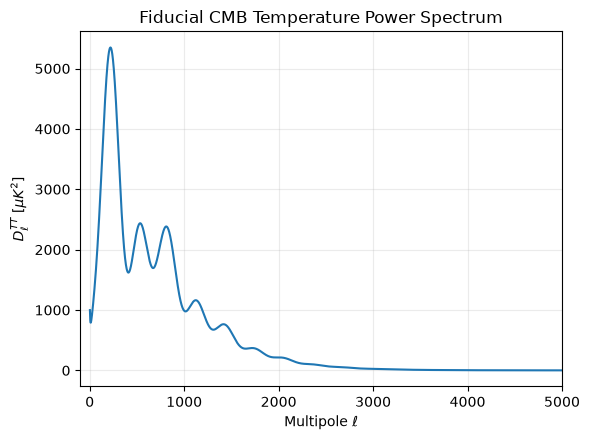

In [3]:
ell, DlTT = np.loadtxt("CAMB_fiducial_cosmo_scalCls.dat", usecols=(0, 1), unpack=True)
print(max(ell))
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.plot(ell[2:], DlTT[2:], color="C0")
ax.set_xlim(-100, 5000)
ax.set_xlabel(r"Multipole $\ell$")
ax.set_ylabel(r"$D_\ell^{TT}$ [$\mu K^2$]")
ax.set_title("Fiducial CMB Temperature Power Spectrum")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


In [4]:
npix = hp.nside2npix(nside)
resolution = hp.nside2resol(nside, arcmin=True)
print(f"NPIX: {npix}, Resolution: {resolution} arcmin")

cls_input = np.loadtxt("CAMB_fiducial_cosmo_scalCls.dat", usecols=(0,1,2,3), unpack=True)
print(np.shape(cls_input))
# # Create a blank map using the Cl array
map_ring = hp.synfast(cls_input, nside=nside)
output_map = 1e-6 * hp.reorder(map_ring, inp='RING', out='NEST')  # Convert to NESTED ordering and scale to microK  

NPIX: 805306368, Resolution: 0.42943580147717575 arcmin
(4, 5001)


Because the high resolution full sky map is really big (like 30GB) we want to mask the excess parts of the sky before writing.

In [5]:
# Find the vector that points to our target center
vec = hp.ang2vec(lon.value, lat.value, lonlat=True)

# Convert the sky coordinates to pixel indices in the HEALPix map
# Find the indices of all the pixels within x degrees of that point
pixel_inds = hp.query_disc(nside, vec=vec, radius=(25*u.deg).to(u.rad).value, nest=True)

# Create a blank map filled with HEALPix UNSEEN values
partial_map = np.full_like(output_map, fill_value=hp.UNSEEN)

# Copy over only the pixel subset data
for i in range(3):
    partial_map[i, pixel_inds] = output_map[i, pixel_inds]

setting the output map dtype to [dtype('float64'), dtype('float64'), dtype('float64')]
setting the output map dtype to [dtype('float64'), dtype('float64'), dtype('float64')]


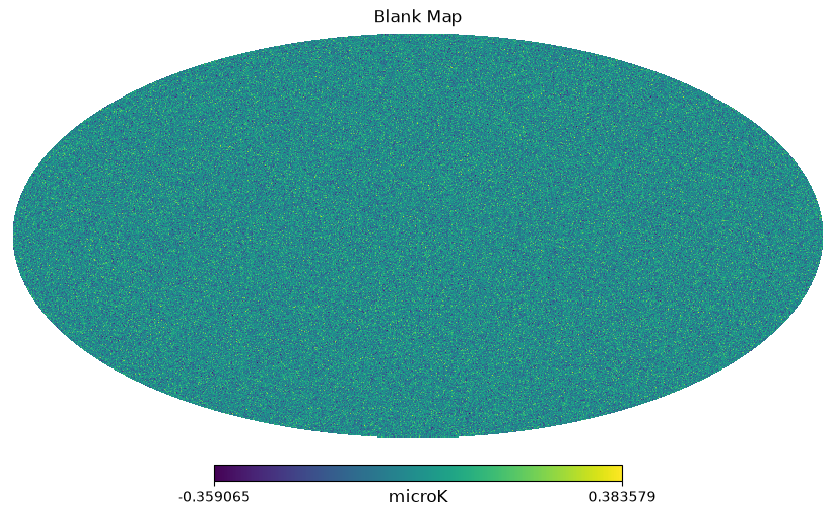

In [64]:
# Save the blank map to a FITS file
output_file = os.path.join(out_dir, f"{res}_cl_map_nosource.fits")

# Save as a standard HEALPix FITS map
hp.write_map(os.path.join(out_dir, f"{res}_partial_{SSO}.fits"), 
             partial_map, 
             overwrite=True, 
             extra_header=[("PIXTYPE", "HEALPIX")], # Optional tracking metadata
             partial=True)

hp.write_map(output_file, output_map, nest=True, overwrite=True)
hp.mollview(output_map[0], title="Blank Map", unit="microK", nest=True)

# Adding A Point Source

In [6]:
# Load the empty map
output_file = os.path.join(out_dir, f"{res}_cl_map_nosource.fits")
output_map = hp.read_map(output_file, nest=True, field=None)

# Find the vector that points to that point
vec = hp.ang2vec(lon.value, lat.value, lonlat=True)

# Convert the sky coordinates to pixel indices in the HEALPix map
# Find the indices of all the pixels within x degrees of that point
pixel_inds = hp.query_disc(nside, vec=vec, radius=source_size.value, nest=True)
# Add a point source to the map at the specified pixel index
output_map[0, pixel_inds] += 8e-1

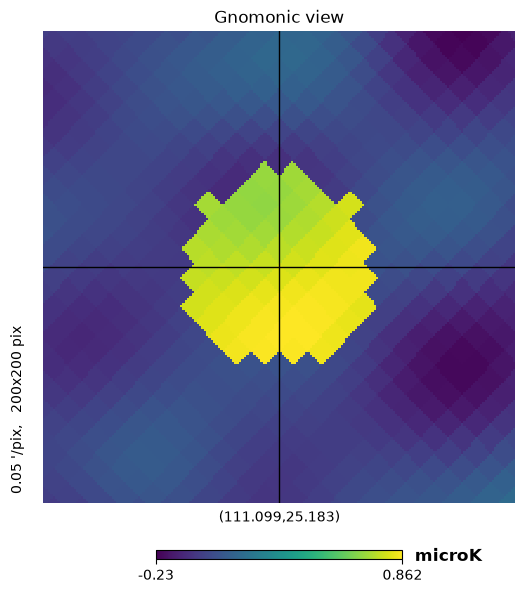

In [7]:
# Convert the vector in theta phi to lon lat
hp.gnomview(output_map[0], rot=[lon.value, lat.value], unit="microK", xsize=200, reso=0.05, nest=True)
hp.graticule()

In [8]:
output_file_with_source = os.path.join(out_dir, f"{res}_cl_map_{int((source_size.to(u.arcmin)).value)}arcmin.fits")
print(np.shape(output_map))
hp.write_map(output_file_with_source, output_map, nest=True, overwrite=True)

setting the output map dtype to [dtype('float64'), dtype('float64'), dtype('float64')]


(3, 805306368)
